# Nugget 2 — Rating NCAA Volleyball Players with TrueSkill
**APMA 4903 · Seminar in Applied Mathematics · Group Project: Predicting Volleyball Outcomes**

---
## 0. Nugget 2 Objective

**Nugget 2 Question:** *Can we rate individual volleyball players using only who beat whom (TrueSkill), and do those ratings predict future matches?*

**Step-by-Step Process:**

| Step | What happens | Why |
|---|---|---|
| 1 | Load the **same** NCAA Division I box scores and match results as Nugget 3 (2022–2025) | Same matches in, so Nugget 4 can compare the two rating systems fairly |
| 2 | Turn each team into a *weighted sum of its players*; a player's weight = her share of the team's past playing time (scaled so every team has six on-court spots) | Results are only known for **teams**, but we want ratings for **players** |
| 3 | Model a match: every player has a Gaussian skill belief $N(\mu,\sigma^2)$; team performance is the weighted sum; $P(\text{A wins})=\Phi(\cdot)$ (Section 3) | This is the TrueSkill model, adapted to partial playing time |
| 4 | After each result, update every involved player's belief with the **truncated-Gaussian** (moment-matching) formulas, **implemented from scratch** and checked against the `trueskill` library (Section 4) | The mathematical core of the nugget |
| 5 | Walk through time day by day: predict first, update afterwards; then *prove* there is no leakage by scrambling the future (Section 5) | A forecast is only honest if it never peeks |
| 6 | Tune the dials on the 2024 season, grade once on the 2025 season with log-loss / Brier / accuracy + bootstrap intervals (Sections 6–7) | Same protocol as Nugget 3 |
| 7 | Analysis: sensitivity to $\sigma_0,\beta,\tau$, how uncertainty shrinks, calibration, rating trajectories, and alternative weighting choices (Section 8) | Shows *why* the model behaves as it does |
| 8 | Rankings of players and teams (Section 9) | A deliverable |
| 9 | Export predictions in the agreed format and compare with Nugget 3 (Section 10) | The plug for Nugget 4 |

**The Core Idea of Nugget 2: what "skill" means.** TrueSkill infers skill **only from win/loss results**: it never looks at kills, digs or aces. Each player carries a *belief* about her own skill — a best guess $\mu$ and an honesty measure $\sigma$ (how unsure we still are). Every result nudges the beliefs of the players who took part: a surprising result moves them a lot, an expected result moves them a little, and every result makes the beliefs more certain. Nugget 3 asks the same prediction question using box-score statistics instead; Nugget 4 compares the two.

**Division of labour inside the project.** Nugget 1 owns the theory (Bradley–Terry, Bayes, the Gaussian skill model). This notebook re-derives only the pieces that are needed to *run* TrueSkill on volleyball: the partial-play team model (Sections 3.2–3.3) and the update rule (Section 3.4). Coordinate with Nugget 1 so each derivation is presented once.

**About "the current season."** As in Nugget 3, the pre-scraped NCAA files stop at the 2025 (2025–26) season. We pretend to stand at the start of 2025 with only the earlier history, predict its matches one day at a time, and grade ourselves. The same code produces forward-looking ratings once 2026 data is added.

## 1. Setup and settings

This section loads the libraries and defines the settings. The seasons and the train/validation/test split are **identical to Nugget 3**.

- `trueskill` is a well-known open-source implementation. We do **not** use it to produce ratings; we only use it in Section 4 as an independent reference to check our own implementation.
- `scipy.special.ndtr` is the normal CDF $\Phi$; `log_ndtr` is its logarithm (numerically stable for extreme values).

In [1]:
# ---------- Libraries ----------
import os, time, copy, warnings
import numpy as np                    # fast math on arrays
import pandas as pd                   # spreadsheets inside Python ("DataFrames")
import matplotlib.pyplot as plt       # charts
from math import sqrt
from scipy.special import log_ndtr, ndtr    # log of the normal CDF (stable) and the normal CDF Phi itself

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# The reference implementation we check ourselves against (it is NOT used to produce any rating below)
try:
    import trueskill
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "trueskill"], check=True)
    import trueskill

# ---------- Settings (same as Nugget 3, so both nuggets are graded on exactly the same matches) ----------
SEASONS       = [2022, 2023, 2024, 2025]   # 2022 = the 2022-23 season
TEST_SEASON   = 2025                       # the "current" season we predict and grade
VALID_SEASON  = 2024                       # the season used to TUNE the dials (never the test season!)
RANDOM_SEED   = 42

BASE_URL = ("https://media.githubusercontent.com/media/JeffreyRStevens/ncaavolleyballr/"
            "refs/heads/main/data-csv/")   # pre-scraped NCAA files (ncaavolleyballr package, MIT license)
DATA_DIR = "data"                          # local folder where a copy is saved so we only download once
os.makedirs(DATA_DIR, exist_ok=True)
np.random.seed(RANDOM_SEED)
print("Setup complete. Seasons:", SEASONS, "| validation:", VALID_SEASON, "| test:", TEST_SEASON, "| trueskill", trueskill.__version__)

Setup complete. Seasons: [2022, 2023, 2024, 2025] | validation: 2024 | test: 2025 | trueskill 0.4.5


## 2–4. Data: download, clean, build one row per match
These three cells are **copied unchanged from Nugget 3 (Sections 2–4)** so that Nugget 2 and Nugget 3 work on exactly the same table of matches. In short: `pm` has one row per player per match (with the number of sets she played, her position and her counting stats), and `matches` has one row per match with the two teams `A`/`B` (A = alphabetically first team), who won (`A_won`) and who was at home (`Home` = +1 if A hosted, −1 if A travelled, 0 if unknown).

*Reminder of a data quirk (see Nugget 3, Section 11):* in the 2022–2024 files each match's box score is stored from **one** team's side only, whereas 2025 stores both. So for many early matches we only know the roster of one of the two teams. Our model is built so that it never needs today's roster of either team (Section 3.2).

In [2]:
# (copied unchanged from Nugget 3, Section 2)
def load_csv(kind, year):
    # Build the file name the same way the package authors did, e.g. wvb_playermatch_div1_2025.csv
    fname = f"wvb_{kind}_div1_{year}.csv"
    local_path = os.path.join(DATA_DIR, fname)       # where our saved copy would be
    if os.path.exists(local_path):                   # if we already downloaded it before...
        return pd.read_csv(local_path)               # ...just read the saved copy
    df = pd.read_csv(BASE_URL + fname)               # otherwise download from GitHub
    df.to_csv(local_path, index=False)               # and save a copy for next time
    return df

player_frames, team_frames = [], []                  # creates two empty lists; we'll drop each season's table into them
for yr in SEASONS:                                   # for each season...
    p = load_csv("playermatch", yr)                  # download the season's player box scores
    t = load_csv("teammatch", yr)                    # download the season's team results
    p["SeasonYear"] = yr                             # add a column recording which season this is
    t["SeasonYear"] = yr
    player_frames.append(p)                          # put p into the empty list player_frames
    team_frames.append(t)                            # put t into the empty list team_frames
    print(f"{yr}: {len(p):,} player-match rows, {len(t):,} team-match rows")      #print the size of data for each season below

pm = pd.concat(player_frames, ignore_index=True)     # define pm = all seasons' player tables stacked into a single table
tm = pd.concat(team_frames, ignore_index=True)       # define tm = all seasons' player team results stacked into a single table
print("\nTotal player-match rows:", f"{len(pm):,}")
pm.head(8)                                           # previews the first 8 rows below

2022: 57,059 player-match rows, 10,305 team-match rows


2023: 56,897 player-match rows, 10,256 team-match rows


2024: 57,902 player-match rows, 10,291 team-match rows


2025: 70,122 player-match rows, 9,221 team-match rows

Total player-match rows: 241,980


,team,Season,Date,Team,Conference,Opponent Team,Opponent Conference,Location,Number,Player,P,S,Kills,Errors,TotalAttacks,HitPct,Assists,Aces,SErr,Digs,RetAtt,RErr,BlockSolos,BlockAssists,BErr,TB,PTS,BHE,SeasonYear,ContestID
0,Boston College,2022-2023,2022-08-26,Boston College,ACC,Siena,MAAC,Away,3,Kate Brennan,MB,3,7,1,9,0.667,1,4,1,2,0,0,0,1,0,0.5,11.5,0,2022,NaN
1,Boston College,2022-2023,2022-08-26,Boston College,ACC,Siena,MAAC,Away,12,Izzy Clavenna,OH,3,7,1,15,0.400,0,0,0,5,1,0,0,1,0,0.5,7.5,0,2022,NaN
2,Boston College,2022-2023,2022-08-26,Boston College,ACC,Siena,MAAC,Away,11,Alayna Crabtree,OH,3,8,2,19,0.316,0,2,0,3,13,1,0,2,0,1.0,11.0,0,2022,NaN
3,Boston College,2022-2023,2022-08-26,Boston College,ACC,Siena,MAAC,Away,18,Bridget Green,L,3,0,0,1,0.000,1,0,1,9,2,0,0,0,0,0.0,0.0,0,2022,NaN
4,Boston College,2022-2023,2022-08-26,Boston College,ACC,Siena,MAAC,Away,23,Julia Haggerty,MB,3,7,1,11,0.545,0,0,0,0,2,0,1,7,0,4.5,11.5,0,2022,NaN
5,Boston College,2022-2023,2022-08-26,Boston College,ACC,Siena,MAAC,Away,9,Katrina Jensen,OH,3,7,2,17,0.294,0,0,0,0,9,1,0,3,0,1.5,8.5,0,2022,NaN
6,Boston College,2022-2023,2022-08-26,Boston College,ACC,Siena,MAAC,Away,10,Peyton Minyard,MB,1,2,0,2,1.000,0,0,0,1,0,0,0,0,0,0.0,2.0,0,2022,NaN
7,Boston College,2022-2023,2022-08-26,Boston College,ACC,Siena,MAAC,Away,4,Anna Murphy,L,3,0,0,0,0.000,1,0,1,8,14,1,0,0,0,0.0,0.0,0,2022,NaN


In [3]:
# (copied unchanged from Nugget 3, Section 3)
pm["Date"] = pd.to_datetime(pm["Date"])                       # convert date text into real date values

# Create the columns that hold counting stats
stat_cols = ["S",
             "Kills",
             "Errors",
             "TotalAttacks",
             "Assists",
             "Aces",
             "SErr",
             "Digs",
             "RetAtt",
             "RErr",
             "BlockSolos",
             "BlockAssists"]
for c in stat_cols:
    pm[c] = pd.to_numeric(pm[c], errors="coerce").fillna(0)   # convert these text values into number values + convert blanks to 0s

pm["Blocks"] = pm["BlockSolos"] + 0.5 * pm["BlockAssists"]    # defines # of blocks = # solo blocks + # assisted blocks (quantified as half a block)

# Merge position labels into 5 groups
pos_map = {"S": "S",
           "OH": "OH",
           "MB": "MB", "MH": "MB",                            # defines middle blockers (MB) to include middle blockers (MB) and middle hitters (MH)
           "OPP": "OPP", "RS": "OPP",                         # defines opposites (OPP) to include opposites (OPP) and right sides (RS)
           "L": "DB", "DS": "DB", "L/DS": "DB"}               # defines defensive backrows (DB) to include liberos (L), defensive specialists (DS), and liberos/defensive specialists (L/DS)
pm["Pos"] = pm["P"].map(pos_map).fillna("OH")                 # use the labels above for the "Pos" column in pm. if a label is unknown, it defaults to outside hitter (OH)

# Remove players who played 0 sets & sort matches chronologically
pm = pm[pm["S"] > 0].copy()                                   # keep only players who played at least 1 set
pm = pm.sort_values("Date").reset_index(drop=True)            # sort the whole table chronologically from oldest -> newest

# To build each player's stat-based skill score, we define the 8 per-set statistics ("features") below
FEATURES = ["Kills", "AtkErr", "Assists", "Aces", "ServeErr", "Digs", "Blocks", "RecErr"]
pm["AtkErr"]   = pm["Errors"]     # defines attack errors
pm["ServeErr"] = pm["SErr"]       # defines serve errors
pm["RecErr"]   = pm["RErr"]       # defines reception (serve-receive) errors

# Sign of each feature: +1 means "more is good", -1 means "more is bad".
SIGN = {"Kills": +1,
        "AtkErr": -1,
        "Assists": +1,
        "Aces": +1,
        "ServeErr": -1,
        "Digs": +1,
        "Blocks": +1,
        "RecErr": -1}

print("Positions:", pm["Pos"].value_counts().to_dict())
print("Date range:", pm["Date"].min().date(), "to", pm["Date"].max().date())
pm[["Date", "Team", "Player", "Pos", "S"] + FEATURES].head(6)

Positions: {'OH': 86886, 'MB': 54174, 'DB': 53058, 'S': 40020, 'OPP': 7840}
Date range: 2022-08-26 to 2025-12-21


,Date,Team,Player,Pos,S,Kills,AtkErr,Assists,Aces,ServeErr,Digs,Blocks,RecErr
0,2022-08-26,Boston College,Kate Brennan,MB,3,7,1,1,4,1,2,0.5,0
1,2022-08-26,Central Ark.,Allison Holloway,MB,2,4,1,0,0,3,0,0.5,0
2,2022-08-26,Central Ark.,Caylan Koons,S,4,2,2,49,0,1,14,0.0,0
3,2022-08-26,Central Ark.,Leigh Maher,DB,4,0,0,2,1,1,22,0.0,0
4,2022-08-26,Central Ark.,Marissa McKelvey,S,1,0,0,2,0,0,0,0.0,0
5,2022-08-26,Central Ark.,Alexis Stumbough,OH,4,4,3,1,2,1,6,1.0,3


In [4]:
# (copied unchanged from Nugget 3, Section 4)
# ---- Step 4a: Clean the Team Results Table ----

# The Date column in the team file looks like "08/30/2025" and sometimes has extra text like "(2)". Pull out just the date part.
tm["DateClean"] = pd.to_datetime(tm["Date"].astype(str).str.extract(r"(\d+/\d+/\d+)")[0],
                                 format="%m/%d/%Y", errors="coerce")
tm = tm[tm["Result"].astype(str).str[0].isin(["W", "L"])].copy()    # keep only rows that are a Win or a Loss
tm["won"] = (tm["Result"].str[0] == "W").astype(int)                # 1 if the team won, 0 if it lost
tm = tm[~tm.duplicated(["Team", "DateClean"], keep=False)].copy()   # drop ambiguous team-days (two matches same day)
results = tm[["Team", "DateClean", "won"]].rename(columns={"DateClean": "Date"})  # keep just what we need

# ---- Step 4b: one row per (team, opponent, date) from the player box scores ----

# NOTE: in the 2022-2024 files, each match appears only once (from one team's side only), however, in 2025, the matches appear from BOTH sides. So we must not require both sides to exist.
rows = (pm.groupby(["SeasonYear", "Team", "Opponent Team", "Date"])
          .agg(Location=("Location", "first"))                # keep whether this team was Home or Away
          .reset_index())

d1_teams = set(pm["Team"].unique())                           # every team that has box scores = the Division I teams in our data
rows = rows[rows["Opponent Team"].isin(d1_teams)].copy()      # keep only matches against a team we also have history for

rows = rows.merge(results, on=["Team", "Date"], how="left")   # attach this team's result (if we found one)

# Make a flipped copy: the same match seen from the OPPONENT's side (exists only if their box score is in the data).
flipped = rows.rename(columns={"Team": "Opponent Team", "Opponent Team": "Team",
                               "won": "opp_won", "Location": "opp_loc"})
flipped = flipped[["SeasonYear", "Team", "Opponent Team", "Date", "opp_won", "opp_loc"]]
rows = rows.merge(flipped, on=["SeasonYear", "Team", "Opponent Team", "Date"], how="left")   # left = keep matches even if no mirror row

# Fill in this team's result from the opponent's result when needed (opponent won -> we lost).
rows["won_final"] = rows["won"].fillna(1 - rows["opp_won"])
# Result of the *opponent's* side could also come directly from the results table (covers matches with no mirror box score).
res_lookup = results.set_index(["Team", "Date"])["won"].to_dict()
missing = rows["won_final"].isna()
rows.loc[missing, "won_final"] = [1 - res_lookup[(o, d)] if (o, d) in res_lookup else np.nan
                                  for o, d in zip(rows.loc[missing, "Opponent Team"], rows.loc[missing, "Date"])]
rows = rows[rows["won_final"].notna()].copy()            # drop matches where nobody's result could be read

# Put each match in a standard orientation: A = whichever team name comes first alphabetically.
flip = rows["Team"] > rows["Opponent Team"]               # True where this row lists the alphabetically-later team first
rows["A"] = np.where(flip, rows["Opponent Team"], rows["Team"])
rows["B"] = np.where(flip, rows["Team"], rows["Opponent Team"])
rows["A_won"] = np.where(flip, 1 - rows["won_final"], rows["won_final"])   # flip the result if we swapped the teams

# Home indicator from A's point of view: +1 if A is home, -1 if A is away, 0 if unknown.
loc_this = rows["Location"].map({"Home": 1.0, "Away": -1.0}).fillna(0.0)   # +1 if THIS row's team was home
rows["Home"] = np.where(flip, -loc_this, loc_this)

# The same match may now appear twice (once from each side) -> keep one copy.
matches = rows.drop_duplicates(["A", "B", "Date"])[["SeasonYear", "Date", "A", "B", "A_won", "Home"]]
matches = matches.sort_values("Date").reset_index(drop=True)
matches["A_won"] = matches["A_won"].astype(int)

print("Number of matches with a known winner (Division I vs Division I):")
print(matches.groupby("SeasonYear").size().to_string())
print("\nShare of matches won by A (should be close to 50% because A is alphabetical = arbitrary):",      # "Share won by A" should be near 0.50. If it were e.g. 0.80, our labeling would be leaking the answer. (Alphabetical order has nothing to do with who wins, so ~0.50 means we're safe.)
      round(matches["A_won"].mean(), 3))
matches.head()

Number of matches with a known winner (Division I vs Division I):
SeasonYear
2022    4357
2023    4629
2024    4698
2025    4477

Share of matches won by A (should be close to 50% because A is alphabetical = arbitrary): 0.494


,SeasonYear,Date,A,B,A_won,Home
0,2022,2022-08-26,Coppin St.,N.C. A&T,1,-1.0
1,2022,2022-08-26,Gardner-Webb,Saint Francis,1,-1.0
2,2022,2022-08-26,Texas Southern,UIW,0,-1.0
3,2022,2022-08-26,Elon,Liberty,0,-1.0
4,2022,2022-08-26,Morehead St.,Queens (NC),1,1.0


## 3. The model: TrueSkill with partial playing time

### 3.1 What each player carries around
Every player $i$ has a **belief** about her own skill $s_i$:

$$s_i \sim N(\mu_i,\ \sigma_i^2)$$

$\mu_i$ is our current best guess, $\sigma_i$ says how unsure we still are. A brand-new player starts at $N(\mu_0,\sigma_0^2)$ with $\mu_0=25$ (the number 25 is arbitrary; only differences matter).

In any single match, a player does not perform exactly at her skill; she has a good or a bad day. TrueSkill models this as
$$p_i \mid s_i \sim N(s_i,\ \beta^2),$$
where $\beta$ is the size of the match-to-match "form" noise.

### 3.2 From players to a team (partial play)
Results are recorded for **teams**, so we need a rule for how a team's performance comes from its players' performances.

- **Playing-time share.** For each player, $f_i=\dfrac{\text{sets she has played so far}}{\text{sets her team has played so far}}$ (at most 1). Only **past** matches are used — never today's lineup (the same "no peeking" rule as Nugget 3; it also solves the problem that for many matches we do not know who played for one of the two teams).
- **Six on-court spots.** Raw shares add up to more than 6, because a substitute who appears in a set counts as having played that set. A deeper bench would therefore give a team a free head start. We rescale so that every team's weights add up to exactly six, the number of players on a court:
$$w_i=6\cdot\frac{f_i}{\sum_{j\in\text{team}} f_j}$$
- **Team performance** is the weighted sum of the players' performances: $t_A=\sum_{i\in A} w_i\,p_i$. This is the "partial play" extension of TrueSkill (Herbrich, Minka & Graepel, 2006): a player who plays half the time counts half.

### 3.3 Win probability before the match
Let $d=t_A-t_B+h\cdot\text{Home}$, the performance gap, with a home-court bonus $h$ (Home = +1, −1 or 0 as in `matches`). Because $d$ is a linear combination of independent Gaussians, it is Gaussian:

$$d\sim N(\mu_d,\ c^2),\qquad \mu_d=\sum_{i\in A}w_i\mu_i-\sum_{j\in B}w_j\mu_j+h\,\text{Home},\qquad c^2=\sum_{i\in A}w_i^2(\sigma_i^2+\beta^2)+\sum_{j\in B}w_j^2(\sigma_j^2+\beta^2).$$

Team A wins if $d>0$, so

$$P(A\text{ beats }B)=P(d>0)=\Phi\!\left(\frac{\mu_d}{c}\right).$$

Two things to notice. (i) The more uncertain the beliefs ($\sigma$ large) the larger $c$, so the closer the probability is to 50%. (ii) This is a **probit** model ($\Phi$), whereas Bradley–Terry in Nugget 1 is **logistic**: both are S-shaped curves of the skill gap, but they are different functions.

### 3.4 Updating beliefs after a result (the mathematical core)
Suppose we now learn that **A won**, i.e. $d>0$. How should the belief about each player change?

1. **Joint Gaussian.** $s_i$ and $d$ are both built from Gaussians, so $(s_i,d)$ is jointly Gaussian. For a player on team A, $\operatorname{Cov}(s_i,d)=w_i\sigma_i^2$; for a player on team B it is $-w_j\sigma_j^2$. Call this covariance $C_i$.
2. **If we knew $d$ exactly**, ordinary Gaussian conditioning would give
$$E[s_i\mid d]=\mu_i+\frac{C_i}{c^2}(d-\mu_d),\qquad \operatorname{Var}(s_i\mid d)=\sigma_i^2-\frac{C_i^2}{c^2}.$$
3. **But we only know $d>0$.** The gap $d$ is a Gaussian *cut off at 0*. With $t=\mu_d/c$, the standard truncated-normal moments are
$$E[d\mid d>0]=\mu_d+c\,v(t),\qquad \operatorname{Var}(d\mid d>0)=c^2\big(1-w(t)\big),$$
$$v(t)=\frac{\varphi(t)}{\Phi(t)},\qquad w(t)=v(t)\big(v(t)+t\big),$$
where $\varphi$ is the standard normal density.
4. **Combine with the laws of total expectation and total variance** (average step 2 over the truncated $d$ of step 3):
$$E[s_i\mid d>0]=\mu_i+\frac{C_i}{c}\,v(t),\qquad \operatorname{Var}(s_i\mid d>0)=\sigma_i^2-\frac{C_i^2}{c^2}\,w(t).$$
5. **Plug in $C_i=\pm w_i\sigma_i^2$.** For a player on the **winning** team and on the **losing** team respectively,
$$\boxed{\ \mu_i\leftarrow\mu_i\pm\frac{w_i\sigma_i^2}{c}\,v(t),\qquad \sigma_i^2\leftarrow\sigma_i^2\Big(1-\frac{w_i^2\sigma_i^2}{c^2}\,w(t)\Big)\ }$$
(plus sign for winners, minus sign for losers; the variance formula is the same for both).

The exact posterior of $s_i$ is slightly skewed, not Gaussian. TrueSkill replaces it by the Gaussian with the **same mean and variance** ("moment matching"). That is the only approximation, and it is what makes the update a few lines of code.

**Reading the formula.** $v(t)$ is large when $t$ is very negative, i.e. when the winner was a heavy underdog: a big upset moves ratings a lot, an expected result hardly any. A player with large $\sigma_i$ (we are unsure about her) moves more than a veteran with small $\sigma_i$. The weight $w_i$ gives credit in proportion to playing time. Since $0<w(t)<1$, the variance can only shrink: every result teaches us something.

If B wins instead, we apply the same formulas with the roles of the teams swapped and $\mu_d$ replaced by $-\mu_d$.

### 3.5 Between matches
Skill is not frozen. At the start of each new season we (a) let uncertainty grow, $\sigma_i^2\leftarrow\sigma_i^2+\tau^2$ (players change over a summer: this is the Gaussian random walk $s^{t}\mid s^{t-1}\sim N(s^{t-1},\tau^2)$), (b) optionally pull ratings slightly back towards the average, $\mu_i\leftarrow\mu_0+\rho(\mu_i-\mu_0)$ ($\rho=1$ means no pull), and (c) let the playing-time memory fade by a factor `decay`, since last year's minutes say less about this year's lineup.

### 3.6 Which dials matter? (scale invariance)
If we multiply $\sigma_0,\beta,\tau$ and $h$ by the same constant $k$, every $\mu$ and $\sigma$ in the model is multiplied by $k$ and **every probability stays exactly the same** — we verify this numerically in Section 5. (It holds because each team's weights add up to the same number, six, so the prior mean $\mu_0$ cancels in $\mu_d$.) So only the *ratios* matter. We therefore fix $\beta=25/6$ (the standard TrueSkill value) and tune $\sigma_0$, $\tau$, $h$, `decay` and $\rho$ in Section 6.

### 3.7 A word on what the ratings mean
Team-level results cannot, in general, pin down every individual's skill (if A and B always play together we only learn about $s_A+s_B$). We therefore judge the model by how well it **predicts**, not by claiming that each $\mu_i$ is the player's true talent. Section 8 returns to this.

## 4. Implementation of the update, and proof that it is correct

The two cells below are the whole mathematical engine: `v_w` computes $v(t)$ and $w(t)$, and `match_update` applies the boxed formulas of Section 3.4 to the players on both sides. (`v_w` works with logarithms so that extreme upsets do not underflow to $0/0$.)

In [5]:
LOG_SQRT_2PI = 0.9189385332046727   # log(sqrt(2*pi)), a constant used below


def v_w(t):
    """Truncated-Gaussian correction terms for 'the performance difference d turned out > 0'.
    v(t) = phi(t)/Phi(t)        (how far the mean of d moves, in units of c)
    w(t) = v(t) * (v(t) + t)    (how much the variance of d shrinks, as a fraction of c^2)
    Computed in log-space so that very lopsided matches (t very negative) do not underflow."""
    v = float(np.exp(-0.5 * t * t - LOG_SQRT_2PI - log_ndtr(t)))
    w = v * (v + t)
    return v, min(max(w, 0.0), 1.0 - 1e-12)


def match_update(mu_d, c2, idx_w, w_w, idx_l, w_l, mu, var):
    """Update beliefs (in place) after a match, given the winner/loser rosters.
       mu_d : prior mean of (winner performance - loser performance)   (home advantage already included)
       c2   : prior variance of that difference
       idx_*: array positions of the players on each side;  w_* : their partial-play weights."""
    c = sqrt(c2)
    t = mu_d / c
    v, w = v_w(t)
    for idx, wt, sign in ((idx_w, w_w, +1.0), (idx_l, w_l, -1.0)):
        if idx.size:
            vi = var[idx]
            mu[idx] = mu[idx] + sign * (wt * vi / c) * v           # mean moves up (winner) / down (loser)
            var[idx] = vi * (1.0 - (wt * wt * vi / c2) * w)         # variance always shrinks
    return t

### 4.1 Check 1 — a match we can do by hand
Two brand-new players, $\mu=25$, $\sigma_0=25/3$, $\beta=25/6$, weights 1. Then $c^2=2(\sigma_0^2+\beta^2)$ and $t=0$, so $v(0)=\varphi(0)/\Phi(0)\approx0.798$ and $w(0)=v(0)^2\approx0.637$. The formulas predict the winner rises by $\sigma_0^2v/c\approx4.2$ and both $\sigma$'s fall from 8.33 to about 7.2.

In [6]:
s0, b = 25 / 3, 25 / 6
c2 = 2 * (s0**2 + b**2); c = sqrt(c2)
v, w = v_w(0.0)                                          # t = 0: a perfectly even match
print(f"c = {c:.3f},  v(0) = {v:.4f},  w(0) = {w:.4f}")
print(f"by hand : winner mu = {25 + s0**2 / c * v:.3f},  loser mu = {25 - s0**2 / c * v:.3f},  both sigma = {sqrt(s0**2 * (1 - s0**2 / c2 * w)):.3f}")

mu = np.array([25.0, 25.0]); var = np.array([s0**2, s0**2])
match_update(0.0, c2, np.array([0]), np.array([1.0]), np.array([1]), np.array([1.0]), mu, var)   # player 0 beats player 1
print(f"our code: winner mu = {mu[0]:.3f},  loser mu = {mu[1]:.3f},  both sigma = {np.sqrt(var[0]):.3f}")

env = trueskill.TrueSkill(mu=25, sigma=s0, beta=b, tau=0.0, draw_probability=0.0)    # volleyball has no draws
ra, rb = env.rate_1vs1(env.create_rating(), env.create_rating())
print(f"library : winner mu = {ra.mu:.3f},  loser mu = {rb.mu:.3f},  both sigma = {ra.sigma:.3f}")

c = 13.176,  v(0) = 0.7979,  w(0) = 0.6366
by hand : winner mu = 29.205,  loser mu = 20.795,  both sigma = 7.194
our code: winner mu = 29.205,  loser mu = 20.795,  both sigma = 7.194
library : winner mu = 29.205,  loser mu = 20.795,  both sigma = 7.194


### 4.2 Check 2 — 300 random matches with random partial-play weights
Teams of 1–8 players, random beliefs, random weights. We compare every updated $\mu$ and $\sigma$ with the `trueskill` library's own partial-play update. (The library iterates until a tolerance of $10^{-4}$, so differences of order $10^{-6}$ are expected.)

In [7]:
rng = np.random.default_rng(RANDOM_SEED)
sig0_t, beta_t = 25 / 3, 25 / 6
env = trueskill.TrueSkill(mu=25, sigma=sig0_t, beta=beta_t, tau=0.0, draw_probability=0.0)
worst_mu = worst_sd = 0.0
for trial in range(300):
    nA, nB = rng.integers(1, 9, 2)                                       # team sizes
    muA, muB = rng.normal(25, 6, nA), rng.normal(25, 6, nB)               # random current beliefs
    sdA, sdB = rng.uniform(1, sig0_t, nA), rng.uniform(1, sig0_t, nB)
    wA, wB = rng.uniform(0.15, 1.0, nA), rng.uniform(0.15, 1.0, nB)       # random partial-play weights

    gA = [env.create_rating(m, s) for m, s in zip(muA, sdA)]              # --- the library ---
    gB = [env.create_rating(m, s) for m, s in zip(muB, sdB)]
    weights = {**{(0, i): float(x) for i, x in enumerate(wA)}, **{(1, j): float(x) for j, x in enumerate(wB)}}
    rA, rB = env.rate([gA, gB], ranks=[0, 1], weights=weights)            # team A wins

    mu = np.concatenate([muA, muB]); var = np.concatenate([sdA, sdB]) ** 2    # --- our code ---
    ia, ib = np.arange(nA), np.arange(nA, nA + nB)
    c2 = (wA**2 * (var[ia] + beta_t**2)).sum() + (wB**2 * (var[ib] + beta_t**2)).sum()
    match_update(wA @ muA - wB @ muB, c2, ia, wA, ib, wB, mu, var)

    lib_mu = np.array([r.mu for r in rA] + [r.mu for r in rB]); lib_sd = np.array([r.sigma for r in rA] + [r.sigma for r in rB])
    worst_mu = max(worst_mu, np.abs(mu - lib_mu).max()); worst_sd = max(worst_sd, np.abs(np.sqrt(var) - lib_sd).max())
print(f"Largest difference to the library over 300 random matches:  mu {worst_mu:.2e},  sigma {worst_sd:.2e}")

Largest difference to the library over 300 random matches:  mu 3.57e-06,  sigma 9.24e-06


## 5. Walking forward through the NCAA seasons

### 5.1 The idea (same discipline as Nugget 3)
We loop over **every calendar day in order**. For each day:

0. **Register** players who appear in a box score for the first time (they start at $N(\mu_0,\sigma_0^2)$).
1. **Predict** every match of the day from the beliefs built **only from earlier days** (Section 3.3). The weights come from past playing time.
2. **Update** the beliefs of both teams' players with the result (Section 3.4).
3. **Only then** add the day's box scores to the playing-time memory.

At each new season the memory fades and uncertainty grows (Section 3.5). A team we have never seen is treated as six average players.

`prepare_data` converts the tables into integer arrays so the loop is fast; `run_walk_forward` is the loop itself. It also has switches that we use later for comparisons: `level="team"` rates whole teams instead of players, `update_weights="actual"` credits the players who really played, `new_prior="team"` starts newcomers at their teammates' average.

In [8]:
def prepare_data(pm, matches):
    """Turn the cleaned box scores (pm) and the match table (matches) into integer-indexed arrays."""
    agg = pm.groupby(["Team", "Date", "Player"], as_index=False, dropna=False)["S"].sum()   # sets per player per day
    team_names = sorted(set(pm["Team"]) | set(matches["A"]) | set(matches["B"]))
    team_id = {t: i for i, t in enumerate(team_names)}
    agg["tid"] = agg["Team"].map(team_id).astype(int)
    agg["pid"], player_keys = pd.factorize(agg["tid"].astype(str) + "||" + agg["Player"].astype(str))
    date_list = sorted(set(agg["Date"]) | set(matches["Date"]))
    date_idx = {d: i for i, d in enumerate(date_list)}
    agg["di"] = agg["Date"].map(date_idx).astype(int)

    box = {}                                       # box[day][team] = (player ids, sets played)
    for (di, tid), g in agg.groupby(["di", "tid"]):
        box.setdefault(di, {})[tid] = (g["pid"].values.astype(int), g["S"].values.astype(float))

    season_of = pm.groupby("Date")["SeasonYear"].first()
    season_of_day = {date_idx[d]: int(s) for d, s in season_of.items() if d in date_idx}

    m_di = matches["Date"].map(date_idx).astype(int).values
    m_by_day = {}
    for i, di in enumerate(m_di):
        m_by_day.setdefault(di, []).append(i)

    return dict(
        n_players=len(player_keys), n_teams=len(team_names), team_names=team_names, team_id=team_id,
        player_keys=player_keys, date_list=date_list, box=box, season_of_day=season_of_day,
        days=sorted(set(box) | set(m_by_day)), m_by_day=m_by_day, n_matches=len(matches),
        A=matches["A"].map(team_id).astype(int).values, B=matches["B"].map(team_id).astype(int).values,
        A_won=matches["A_won"].values.astype(int), Home=matches["Home"].values.astype(float),
        m_season=matches["SeasonYear"].values.astype(int), m_di=m_di)


DEFAULT_PARAMS = dict(mu0=25.0, sigma0=25.0 / 3, beta=25.0 / 6, tau_season=25.0 / 300, home=0.0, decay=0.6, rho=1.0)

W_BAR = 6.0   # a volleyball team always has six players on the court


def on_court_weights(share):
    """Turn raw playing-time shares into partial-play weights that always add up to 6 (the six on-court spots).
    Why: a 'share of the team's sets' counts every player who touched a set, so deeper benches add up to more than 6.
    Without this step a team with a longer rotation would get a free head start (sum of weights x prior mean 25)."""
    return W_BAR * share / share.sum()

In [9]:
def run_walk_forward(D, P, level="player", update_weights="expected", new_prior="global", end_season=None,
                     record=False, fallback=(6.0, 1.9)):
    """Walk through every day in order.  For each day:
         (0) register players seen for the first time,
         (1) predict that day's matches from beliefs built ONLY from earlier days,
         (2) update beliefs with that day's results,
         (3) add that day's box scores to the playing-time memory.
       level          : 'player' (team = weighted sum of its players)  or  'team' (each team is one 'player')
       update_weights : 'expected' (same past-playing-time weights as the prediction)
                        'actual'   (today's real participation, when the box score exists)
       fallback       : (typical sum of weights, typical sum of squared weights) for a team with no history yet"""
    mu0, sig0, beta = P["mu0"], P["sigma0"], P["beta"]
    tau, h, decay, rho = P["tau_season"], P["home"], P["decay"], P["rho"]
    tau_m2 = P.get("tau_match", 0.0) ** 2                                       # drift added per match played
    beta2 = beta * beta
    nU = D["n_players"] if level == "player" else D["n_teams"]
    mu = np.full(nU, float(mu0)); var = np.full(nU, float(sig0) ** 2); seen = np.zeros(nU, bool)
    sets = np.zeros(nU); team_sets = np.zeros(D["n_teams"])
    roster = [[] for _ in range(D["n_teams"])]; roster_np = [None] * D["n_teams"]
    fb_mu = fallback[0] * mu0; fb_V = fallback[1] * (sig0 ** 2 + beta2)      # an all-prior team

    n = D["n_matches"]
    p_out = np.full(n, np.nan); muA_out = np.full(n, np.nan); muB_out = np.full(n, np.nan); c_out = np.full(n, np.nan)
    hist = dict(di=[], pid=[], mu=[], var=[]) if record else None
    one = {}                                                                   # team-level: cached 1-element arrays

    def expected_lineup(tid):
        """(player positions, weights) = each known player's share of the team's past sets."""
        if level == "team":
            if tid not in one: one[tid] = (np.array([tid]), np.array([1.0]))
            return one[tid]
        r = roster_np[tid]
        if r is None:
            r = np.array(roster[tid], dtype=int); roster_np[tid] = r
        ts = team_sets[tid]
        if r.size == 0 or ts <= 0:
            return r[:0], np.zeros(0)
        w = np.minimum(sets[r] / ts, 1.0)
        keep = w > 0
        if not keep.any():
            return r[:0], np.zeros(0)
        return r[keep], on_court_weights(w[keep])

    def stats(idx, w):
        if idx.size == 0:
            return fb_mu, fb_V
        return float(w @ mu[idx]), float((w * w) @ (var[idx] + beta2))

    cur_season = None
    for di in D["days"]:
        season = D["season_of_day"].get(di, cur_season)
        if end_season is not None and season is not None and season > end_season:
            break
        if cur_season is not None and season != cur_season:                  # ---- new season: memory fades, uncertainty grows
            sets *= decay; team_sets *= decay
            mu[seen] = mu0 + rho * (mu[seen] - mu0)
            var[seen] += tau ** 2
        cur_season = season
        todays_box = D["box"].get(di, {})
        todays_matches = D["m_by_day"].get(di, [])

        # (0) first appearances
        if level == "player":
            for tid, (ids, s) in todays_box.items():
                new = ~seen[ids]
                if new.any():
                    nid = ids[new]; seen[nid] = True; var[nid] = sig0 ** 2
                    start = mu0                                              # prior mean of a brand-new player
                    if new_prior == "team":                                  # ...or: the current average of her teammates
                        li, lw = expected_lineup(tid)
                        if li.size: start = float(lw @ mu[li] / lw.sum())
                    mu[nid] = start
                    roster[tid].extend(nid.tolist()); roster_np[tid] = None
        else:
            for i in todays_matches:
                for tid in (D["A"][i], D["B"][i]):
                    if not seen[tid]: seen[tid] = True; mu[tid] = mu0; var[tid] = sig0 ** 2

        # (1) predict + (2) update, for every match played today
        for i in todays_matches:
            a, b = D["A"][i], D["B"][i]
            ia, wa = expected_lineup(a); ib, wb = expected_lineup(b)
            if tau_m2 > 0:                                                       # skill may drift a little between matches
                var[ia] += tau_m2; var[ib] += tau_m2
            mA, VA = stats(ia, wa); mB, VB = stats(ib, wb)
            c2 = VA + VB
            mu_d = mA - mB + h * D["Home"][i]                                   # mean of (perf A - perf B)
            p_out[i] = ndtr(mu_d / sqrt(c2)); muA_out[i] = mA; muB_out[i] = mB; c_out[i] = sqrt(c2)

            if update_weights == "actual" and level == "player":              # use who REALLY played, if we know
                for tid, which in ((a, "a"), (b, "b")):
                    if tid in todays_box:
                        ids, s = todays_box[tid]
                        if which == "a": ia, wa = ids, on_court_weights(s / s.max())
                        else:            ib, wb = ids, on_court_weights(s / s.max())
                mA, VA = stats(ia, wa); mB, VB = stats(ib, wb)
                c2 = VA + VB; mu_d = mA - mB + h * D["Home"][i]
            if D["A_won"][i] == 1:
                match_update(mu_d, c2, ia, wa, ib, wb, mu, var)
            else:
                match_update(-mu_d, c2, ib, wb, ia, wa, mu, var)
            if record:
                for idx in (ia, ib):
                    if idx.size:
                        hist["di"].append(np.full(idx.size, di)); hist["pid"].append(idx)
                        hist["mu"].append(mu[idx].copy()); hist["var"].append(var[idx].copy())

        # (3) memory update with today's box scores
        if level == "player":
            for tid, (ids, s) in todays_box.items():
                sets[ids] += s
                team_sets[tid] += s.max()

    out = dict(p=p_out, muA=muA_out, muB=muB_out, c=c_out, mu=mu, var=var, sets=sets, team_sets=team_sets,
               roster=roster, seen=seen)
    if record:
        out["hist"] = {k: np.concatenate(v) if v else np.array([]) for k, v in hist.items()}
    return out

In [10]:
def log_loss(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return float(np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p))))

def brier(p, y):
    return float(np.mean((p - y) ** 2))

def accuracy(p, y):
    return float(np.mean((p > 0.5) == (y == 1)))

### 5.2 First run with the *standard* TrueSkill settings (no tuning yet)
`DEFAULT_PARAMS` are the textbook TrueSkill values ($\sigma_0=25/3$, $\beta=25/6$, $\tau=25/300$) with no home advantage. The first season is a warm-up (everybody starts equal), so its score is poor; the later seasons show what the model can do.

In [11]:
D = prepare_data(pm, matches)
print(f"{D['n_players']:,} distinct players, {D['n_teams']} teams, {len(D['days'])} match days, {D['n_matches']:,} matches")

y_all = D["A_won"]; m_season = D["m_season"]
valid_mask = m_season == VALID_SEASON
test_mask  = m_season == TEST_SEASON

t0 = time.time()
out_default = run_walk_forward(D, DEFAULT_PARAMS)
print(f"One full walk-forward run takes {time.time() - t0:.1f} seconds.\n")

rows = []
for s in SEASONS:
    m = m_season == s; p = out_default["p"][m]
    rows.append(dict(Season=s, Matches=int(m.sum()), LogLoss=log_loss(p, y_all[m]), Brier=brier(p, y_all[m]), Accuracy=accuracy(p, y_all[m])))
print("Standard TrueSkill settings, predictions made one day at a time (coin flip = 0.693 / 0.250 / 0.50):")
print(pd.DataFrame(rows).round(4).to_string(index=False))

12,078 distinct players, 349 teams, 419 match days, 18,161 matches


One full walk-forward run takes 1.0 seconds.

Standard TrueSkill settings, predictions made one day at a time (coin flip = 0.693 / 0.250 / 0.50):
 Season  Matches  LogLoss  Brier  Accuracy
   2022     4357   0.6027 0.2057    0.6752
   2023     4629   0.5474 0.1799    0.7345
   2024     4698   0.5199 0.1702    0.7482
   2025     4477   0.5390 0.1770    0.7396


### 5.3 Check 3 — no leakage (scramble the future)
If the code never peeks, then changing the outcomes of *future* matches must not change any *earlier* prediction. We replace every result after a cutoff in the middle of 2025 by a coin flip and rerun. We also flip only the results *on* the cutoff day: that day's own predictions must not move, but later days should.

In [12]:
days_test = np.sort(np.unique(D["m_di"][test_mask])); cutoff = days_test[len(days_test) // 2]
print("cutoff date:", pd.Timestamp(D["date_list"][cutoff]).date())

D_future = copy.copy(D); D_future["A_won"] = D["A_won"].copy()
after = D["m_di"] > cutoff; before = ~after
D_future["A_won"][after] = np.random.default_rng(1).integers(0, 2, after.sum())      # future results -> coin flips
alt = run_walk_forward(D_future, DEFAULT_PARAMS)
print(f"Scrambled the {after.sum():,} results after the cutoff:")
print(f"  largest change in any prediction BEFORE/ON the cutoff: {np.nanmax(np.abs(out_default['p'][before] - alt['p'][before])):.1e}   (must be 0)")
print(f"  largest change in predictions AFTER the cutoff        : {np.nanmax(np.abs(out_default['p'][after] - alt['p'][after])):.3f}   (should be large: the model does use past results)")

D_day = copy.copy(D); D_day["A_won"] = D["A_won"].copy(); same_day = D["m_di"] == cutoff
D_day["A_won"][same_day] = 1 - D_day["A_won"][same_day]                              # flip the results ON the cutoff day
alt2 = run_walk_forward(D_day, DEFAULT_PARAMS)
print(f"Flipped the {same_day.sum()} results on the cutoff day itself:")
print(f"  change in that day's own predictions: {np.nanmax(np.abs(out_default['p'][same_day] - alt2['p'][same_day])):.1e}   (must be 0)")
print(f"  change in later predictions         : {np.nanmax(np.abs(out_default['p'][after] - alt2['p'][after])):.3f}")

cutoff date: 2025-10-16


Scrambled the 1,878 results after the cutoff:
  largest change in any prediction BEFORE/ON the cutoff: 0.0e+00   (must be 0)
  largest change in predictions AFTER the cutoff        : 0.982   (should be large: the model does use past results)


Flipped the 31 results on the cutoff day itself:
  change in that day's own predictions: 0.0e+00   (must be 0)
  change in later predictions         : 0.615


### 5.4 Check 4 — the scale-invariance claim of Section 3.6
Multiply $\sigma_0,\beta,\tau,h$ by the same constant ($k=2.7$) and compare all predictions.

In [13]:
P_a = dict(DEFAULT_PARAMS, home=1.0)
k = 2.7
P_b = dict(P_a, sigma0=P_a["sigma0"] * k, beta=P_a["beta"] * k, tau_season=P_a["tau_season"] * k, home=P_a["home"] * k)
pa = run_walk_forward(D, P_a, end_season=2023)["p"]; pb = run_walk_forward(D, P_b, end_season=2023)["p"]
print(f"Largest difference between the two sets of predictions (all matches up to 2023): {np.nanmax(np.abs(pa - pb)):.1e}")

Largest difference between the two sets of predictions (all matches up to 2023): 3.8e-15


## 6. Tuning the dials on the validation season (never on the test season)

Five dials are free: $\sigma_0$ (how unsure we are about a new player), $\tau$ (how much uncertainty is added each new season), $h$ (home advantage, in rating points), `decay` (how fast playing-time memory fades) and $\rho$ (pull towards the average between seasons). $\beta$ is fixed by Section 3.6.

**Method — coordinate search.** Start from the defaults. Take one dial at a time, try a list of values with the others held fixed, keep the best, move to the next dial; make two passes. "Best" = lowest **log-loss on the 2024 season**, using the walk-forward predictions (so 2024 is predicted from 2022–2024 information available at each date; no 2025 data is touched — the loop stops after 2024).

*Why not tune on the test season?* If we picked whatever looks best on 2025 and then reported 2025, the score would be optimistically biased. Tune on 2024, touch 2025 once.

In [14]:
def coordinate_search(P_start, grids, sweeps=2, verbose=True, **engine_kwargs):
    """Tune one dial at a time on the validation season (lowest log-loss wins). Returns the best settings."""
    P = dict(P_start)
    for sweep in range(sweeps):
        for name, values in grids.items():
            scores = []
            for v in values:
                trial = dict(P); trial[name] = v
                out = run_walk_forward(D, trial, end_season=VALID_SEASON, **engine_kwargs)      # stop after the validation season
                scores.append(log_loss(out["p"][valid_mask], y_all[valid_mask]))
            P[name] = values[int(np.argmin(scores))]
            if verbose:
                print(f"pass {sweep + 1} | {name:10s} " + "  ".join(f"{v:g}: {s:.4f}" for v, s in zip(values, scores)) + f"   ->  {P[name]:g}")
    return P

GRID_PLAYER = dict(sigma0=[2, 3, 4, 5, 6, 8.33],
                   tau_season=[0, 0.25, 0.5, 1, 2],
                   home=[1, 1.5, 2, 2.5, 3],
                   decay=[0.4, 0.6, 0.8, 1.0],
                   rho=[0.85, 1.0])

t0 = time.time()
print("Validation log-loss for each value tried (lower is better; coin flip = 0.6931):\n")
P_MAIN = coordinate_search(dict(DEFAULT_PARAMS, home=1.0), GRID_PLAYER)
print(f"\nChosen settings: { {k: round(float(v), 3) for k, v in P_MAIN.items()} }   ({time.time() - t0:.0f} s)")

Validation log-loss for each value tried (lower is better; coin flip = 0.6931):



pass 1 | sigma0     2: 0.5184  3: 0.4975  4: 0.4925  5: 0.4943  6: 0.4991  8.33: 0.5137   ->  4


pass 1 | tau_season 0: 0.4925  0.25: 0.4925  0.5: 0.4925  1: 0.4928  2: 0.4948   ->  0


pass 1 | home       1: 0.4925  1.5: 0.4908  2: 0.4902  2.5: 0.4908  3: 0.4925   ->  2


pass 1 | decay      0.4: 0.4929  0.6: 0.4902  0.8: 0.4885  1: 0.4875   ->  1


pass 1 | rho        0.85: 0.4889  1: 0.4875   ->  1


pass 2 | sigma0     2: 0.5133  3: 0.4927  4: 0.4875  5: 0.4890  6: 0.4937  8.33: 0.5083   ->  4


pass 2 | tau_season 0: 0.4875  0.25: 0.4875  0.5: 0.4875  1: 0.4876  2: 0.4898   ->  0.25


pass 2 | home       1: 0.4896  1.5: 0.4880  2: 0.4875  2.5: 0.4881  3: 0.4899   ->  2


pass 2 | decay      0.4: 0.4929  0.6: 0.4902  0.8: 0.4885  1: 0.4875   ->  1


pass 2 | rho        0.85: 0.4889  1: 0.4875   ->  1

Chosen settings: {'mu0': 25.0, 'sigma0': 4.0, 'beta': 4.167, 'tau_season': 0.25, 'home': 2.0, 'decay': 1.0, 'rho': 1.0}   (32 s)


### How to read this
Each line is one dial; the numbers after each value are the validation log-loss with that value (others held fixed), and the arrow shows the value kept. A flat line (e.g. $\tau$) means the model is insensitive to that dial; a pronounced valley (e.g. $\sigma_0$) means it matters. Where the best value sits at the *edge* of the list (e.g. `decay`=1, no forgetting), we report it as found and look at the whole curve in Section 8.2.

## 7. Final run: grade on the 2025 test season

We lock the settings and score every 2025 match using only information available the day before. To show what each modelling choice buys us we compare several versions, **each tuned separately on 2024 in exactly the same way**:

| Version | What is different |
|---|---|
| **Player-level TrueSkill (MAIN)** | the model of Section 3 |
| + newcomers start at teammates' average | a new player's prior mean is her team's current average instead of 25 |
| + updates use who actually played | after the match, credit the players who really played (when the box score is stored) instead of the playing-time weights |
| Team-level TrueSkill | no players at all: every team is a single "player" with weight 1 (a Gaussian Elo-style rating) |
| Player-level, untuned defaults | MAIN with the textbook settings of Section 5.2 |
| Coin flip | always 50% |

**Uncertainty.** A single log-loss number hides luck. As in Nugget 3 we use the **bootstrap**: resample the 2025 matches with replacement 1,000 times and recompute the metric; the 2.5th–97.5th percentiles form a 95% interval.

In [15]:
GRID_TEAM = dict(sigma0=[6, 8.33, 12, 16, 24],
                 tau_season=[2, 3, 4, 6, 8],
                 tau_match=[0, 0.25, 0.5, 1.0],                  # a little drift after every match (only helps whole teams)
                 home=[0.5, 1, 1.5, 2],
                 rho=[0.85, 1.0])

VARIANTS = {
    "Player-level TrueSkill (MAIN)":                  dict(P=P_MAIN, kwargs={}),
    "  + newcomers start at teammates' average":      dict(P=None, kwargs=dict(new_prior="team"),         grids=GRID_PLAYER),
    "  + updates use who actually played":            dict(P=None, kwargs=dict(update_weights="actual"),  grids=GRID_PLAYER),
    "Team-level TrueSkill (each team = one player)":  dict(P=None, kwargs=dict(level="team"),             grids=GRID_TEAM,
                                                          start=dict(DEFAULT_PARAMS, sigma0=8.33, tau_season=3, home=1.0)),
}
t0 = time.time()
for name, spec in VARIANTS.items():
    if spec["P"] is None:                                                   # tune the comparison versions the same way
        spec["P"] = coordinate_search(spec.get("start", dict(DEFAULT_PARAMS, home=1.0)), spec["grids"], verbose=False, **spec["kwargs"])
    print(f"{name:48s} tuned on {VALID_SEASON}: " + ", ".join(f"{k}={float(v):g}" for k, v in spec["P"].items() if k in ("sigma0", "tau_season", "tau_match", "home", "decay", "rho")))
print(f"({time.time() - t0:.0f} s)")

Player-level TrueSkill (MAIN)                    tuned on 2024: sigma0=4, tau_season=0.25, home=2, decay=1, rho=1


  + newcomers start at teammates' average        tuned on 2024: sigma0=4, tau_season=0, home=2, decay=1, rho=0.85


  + updates use who actually played              tuned on 2024: sigma0=4, tau_season=0.5, home=2, decay=0.4, rho=0.85


Team-level TrueSkill (each team = one player)    tuned on 2024: sigma0=12, tau_season=3, home=1.5, decay=0.6, rho=1, tau_match=0.5
(90 s)


In [16]:
y_test = y_all[test_mask]; n_test = int(test_mask.sum())
rng = np.random.default_rng(RANDOM_SEED)
boot_idx = rng.integers(0, n_test, size=(1000, n_test))                   # 1000 resamples of the test matches

def boot_ci(p, metric):
    vals = [metric(p[ix], y_test[ix]) for ix in boot_idx]
    return np.percentile(vals, [2.5, 97.5])

test_preds = {"Coin flip": np.full(n_test, 0.5)}
final_outs = {}
for name, spec in VARIANTS.items():
    final_outs[name] = run_walk_forward(D, spec["P"], **spec["kwargs"])
    test_preds[name] = final_outs[name]["p"][test_mask]
test_preds["Player-level, untuned defaults"] = out_default["p"][test_mask]

table = []
for name, p in test_preds.items():
    lo, hi = boot_ci(p, log_loss)
    table.append(dict(Model=name.strip(), LogLoss=log_loss(p, y_test), LL_95CI=f"[{lo:.3f}, {hi:.3f}]", Brier=brier(p, y_test), Accuracy=accuracy(p, y_test)))
results_table = pd.DataFrame(table).sort_values("LogLoss").reset_index(drop=True)
print(f"TEST SEASON {TEST_SEASON}-{str(TEST_SEASON + 1)[-2:]}: {n_test} matches (lower log-loss / Brier = better)\n")
print(results_table.round(4).to_string(index=False))

TEST SEASON 2025-26: 4477 matches (lower log-loss / Brier = better)

                                        Model  LogLoss        LL_95CI  Brier  Accuracy
Team-level TrueSkill (each team = one player)   0.4838 [0.467, 0.500] 0.1597    0.7679
      + newcomers start at teammates' average   0.4953 [0.479, 0.511] 0.1642    0.7585
                Player-level TrueSkill (MAIN)   0.4978 [0.482, 0.513] 0.1653    0.7585
            + updates use who actually played   0.5091 [0.493, 0.523] 0.1699    0.7505
               Player-level, untuned defaults   0.5390 [0.519, 0.558] 0.1770    0.7396
                                    Coin flip   0.6931 [0.693, 0.693] 0.2500    0.5106


### Paired comparisons
Overlapping intervals do not settle which model is better, because both models are scored on the *same* matches. The **paired** version looks at the per-match log-loss difference (model A minus model B) and bootstraps its mean: negative = A is better; if the whole interval is on one side of 0 the difference is bigger than luck.

In [17]:
NAMES = {"main": "Player-level TrueSkill (MAIN)", "team": "Team-level TrueSkill (each team = one player)",
         "teamprior": "  + newcomers start at teammates' average", "actual": "  + updates use who actually played"}

def per_match_logloss(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def compare(name_a, name_b, preds, y=None):
    y = y_test if y is None else y
    d = per_match_logloss(preds[name_a], y) - per_match_logloss(preds[name_b], y)
    boots = [d[ix].mean() for ix in boot_idx]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    verdict = "A is better (CI below 0)" if hi < 0 else ("B is better (CI above 0)" if lo > 0 else "no clear difference (CI includes 0)")
    print(f"{name_a.strip()}  vs  {name_b.strip()}:  mean log-loss difference = {d.mean():+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  -> {verdict}")

compare(NAMES["main"], "Coin flip", test_preds)
compare(NAMES["main"], "Player-level, untuned defaults", test_preds)
compare(NAMES["main"], NAMES["team"], test_preds)
compare(NAMES["main"], NAMES["teamprior"], test_preds)
compare(NAMES["main"], NAMES["actual"], test_preds)

Player-level TrueSkill (MAIN)  vs  Coin flip:  mean log-loss difference = -0.1953  95% CI [-0.2112, -0.1804]  -> A is better (CI below 0)
Player-level TrueSkill (MAIN)  vs  Player-level, untuned defaults:  mean log-loss difference = -0.0412  95% CI [-0.0499, -0.0322]  -> A is better (CI below 0)
Player-level TrueSkill (MAIN)  vs  Team-level TrueSkill (each team = one player):  mean log-loss difference = +0.0140  95% CI [+0.0097, +0.0184]  -> B is better (CI above 0)
Player-level TrueSkill (MAIN)  vs  + newcomers start at teammates' average:  mean log-loss difference = +0.0026  95% CI [+0.0007, +0.0043]  -> B is better (CI above 0)
Player-level TrueSkill (MAIN)  vs  + updates use who actually played:  mean log-loss difference = -0.0113  95% CI [-0.0145, -0.0081]  -> A is better (CI below 0)


## 8. Understanding the model

### 8.1 Calibration — when we say 70%, does the team win about 70% of the time?

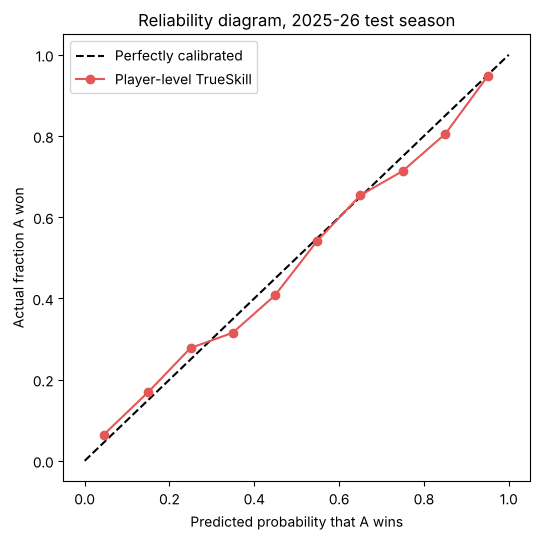

matches per point: [591, 407, 439, 406, 410, 388, 425, 412, 432, 567]


In [18]:
p_main = test_preds[NAMES["main"]]
bins = np.linspace(0, 1, 11)
which = np.digitize(p_main, bins) - 1
xs, ys, ns = [], [], []
for b_ in range(10):
    mask = which == b_
    if mask.sum() >= 15:
        xs.append(p_main[mask].mean()); ys.append(y_test[mask].mean()); ns.append(int(mask.sum()))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
ax.plot(xs, ys, "o-", color="#E45756", label="Player-level TrueSkill")
ax.set_xlabel("Predicted probability that A wins"); ax.set_ylabel("Actual fraction A won")
ax.set_title("Reliability diagram, 2025-26 test season"); ax.legend(); plt.tight_layout(); plt.show()
print("matches per point:", ns)

**How to read it.** Points on the dashed diagonal mean the stated probabilities are honest. Points *above* the diagonal on the right (and below on the left) would mean the model is *under*-confident; the opposite pattern means over-confident.

### 8.2 Sensitivity analysis — how much does each dial matter?
We vary one dial at a time around the chosen settings and plot the log-loss on the validation season (2024, which was used to choose them) and on the test season (2025, **shown only to judge robustness, never used to choose**). $\beta$ is included even though it is redundant with the others in the sense of Section 3.6: changing $\beta$ *alone* changes the ratios $\sigma_0/\beta$, $\tau/\beta$, $h/\beta$.

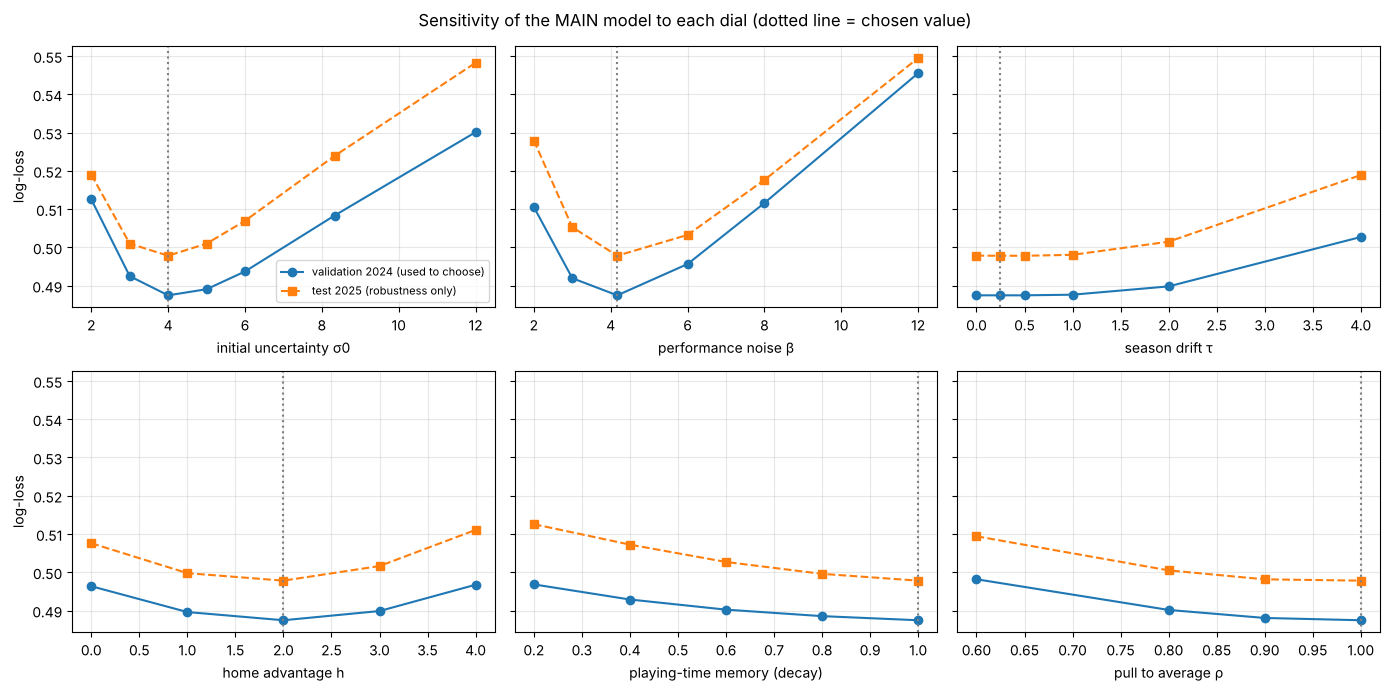

(30 s)


In [19]:
SENS = dict(sigma0=[2, 3, 4, 5, 6, 8.33, 12], beta=[2, 3, 4.17, 6, 8, 12], tau_season=[0, 0.25, 0.5, 1, 2, 4],
            home=[0, 1, 2, 3, 4], decay=[0.2, 0.4, 0.6, 0.8, 1.0], rho=[0.6, 0.8, 0.9, 1.0])
LABEL = dict(sigma0="initial uncertainty σ0", beta="performance noise β", tau_season="season drift τ",
             home="home advantage h", decay="playing-time memory (decay)", rho="pull to average ρ")
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
t0 = time.time()
for ax, (name, values) in zip(axes.ravel(), SENS.items()):
    v_ll, t_ll = [], []
    for v in values:
        out = run_walk_forward(D, dict(P_MAIN, **{name: v}))
        v_ll.append(log_loss(out["p"][valid_mask], y_all[valid_mask])); t_ll.append(log_loss(out["p"][test_mask], y_all[test_mask]))
    ax.plot(values, v_ll, "o-", label="validation 2024 (used to choose)"); ax.plot(values, t_ll, "s--", label="test 2025 (robustness only)")
    ax.axvline(P_MAIN[name], color="grey", ls=":"); ax.set_xlabel(LABEL[name]); ax.grid(alpha=.3)
axes[0, 0].set_ylabel("log-loss"); axes[1, 0].set_ylabel("log-loss"); axes[0, 0].legend(fontsize=8)
fig.suptitle("Sensitivity of the MAIN model to each dial (dotted line = chosen value)"); plt.tight_layout(); plt.show()
print(f"({time.time() - t0:.0f} s)")

### 8.3 How fast does uncertainty shrink?
For every player we follow $\sigma_i$ after her 1st, 2nd, 3rd … rated match and plot the typical value (median and the middle 50% of players). Each result removes some uncertainty (Section 3.4: $\sigma^2$ can only shrink); the small upward steps are the season drift $\tau$ (Section 3.5).

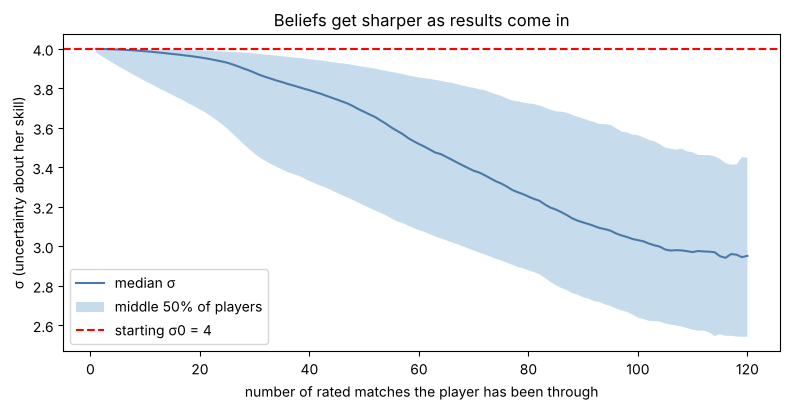

     med   q25   q75      n
k                          
1   4.00  3.98  4.00  12066
5   4.00  3.91  4.00  12032
10  3.99  3.84  4.00  11875
20  3.96  3.69  3.99  11599
40  3.79  3.33  3.95   9050
80  3.25  2.88  3.72   5690


In [20]:
rec = run_walk_forward(D, P_MAIN, record=True)                      # same run, but remember every belief after every update
H = pd.DataFrame(dict(di=rec["hist"]["di"].astype(int), pid=rec["hist"]["pid"].astype(int),
                      mu=rec["hist"]["mu"], sd=np.sqrt(rec["hist"]["var"])))
H["k"] = H.groupby("pid").cumcount() + 1                           # k = how many rated matches this player has been through
curve = H.groupby("k")["sd"].agg(med="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75), n="count")
curve = curve[curve["n"] >= 200].iloc[:120]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(curve.index, curve["med"], color="#4C78A8", label="median σ"); ax.fill_between(curve.index, curve["q25"], curve["q75"], alpha=.25, label="middle 50% of players")
ax.axhline(P_MAIN["sigma0"], color="red", ls="--", label=f"starting σ0 = {P_MAIN['sigma0']:g}")
ax.set_xlabel("number of rated matches the player has been through"); ax.set_ylabel("σ (uncertainty about her skill)")
ax.set_title("Beliefs get sharper as results come in"); ax.legend(); plt.tight_layout(); plt.show()
print(curve.loc[[1, 5, 10, 20, 40, 80]].round(2)[["med", "q25", "q75", "n"]].to_string())

### 8.4 Rating trajectories
**Left:** the belief ($\mu\pm1\sigma$) of the four highest-rated experienced players over time. **Right:** the strength of the five strongest teams across the 2025 season, measured as $\sum_i w_i(\mu_i-25)$ at the start of each of their matches ("rating points above an average team"; 0 = average). Both are built from the information available at that moment — the curves are exactly what the model believed on each day.

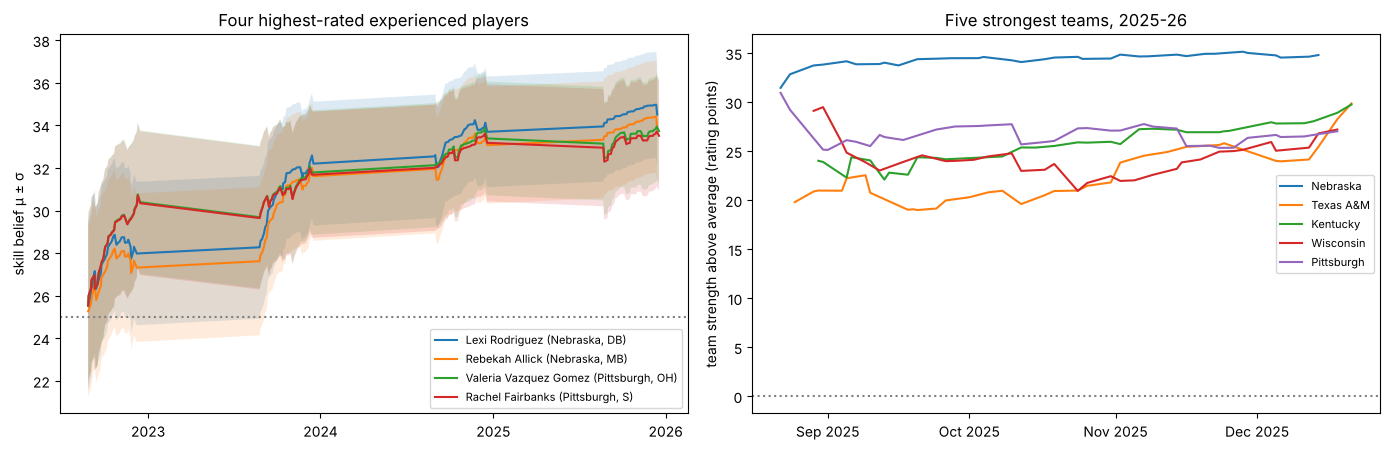

In [21]:
# --- helper tables: who is who ---
pos_last = pm.sort_values("Date").dropna(subset=["Player"]).groupby(["Team", "Player"])["Pos"].last()
def split_key(k):
    tid, name = k.split("||", 1); return D["team_names"][int(tid)], name
players = pd.DataFrame([dict(pid=i, Team=split_key(k)[0], Player=split_key(k)[1]) for i, k in enumerate(D["player_keys"])])
players["Pos"] = [pos_last.get((t, n), "?") for t, n in zip(players["Team"], players["Player"])]
players["Sets"] = rec["sets"][players["pid"].values]; players["mu"] = rec["mu"][players["pid"].values]; players["sigma"] = np.sqrt(rec["var"][players["pid"].values])
players = players[rec["seen"][players["pid"].values]]

top4 = players[players["Sets"] >= 150].sort_values("mu", ascending=False).head(4)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for r in top4.itertuples():
    hh = H[H["pid"] == r.pid]; dates = pd.to_datetime([D["date_list"][d] for d in hh["di"]])
    axes[0].plot(dates, hh["mu"], label=f"{r.Player} ({r.Team}, {r.Pos})"); axes[0].fill_between(dates, hh["mu"] - hh["sd"], hh["mu"] + hh["sd"], alpha=.15)
axes[0].axhline(25, color="grey", ls=":"); axes[0].set_ylabel("skill belief μ ± σ"); axes[0].set_title("Four highest-rated experienced players"); axes[0].legend(fontsize=8)

mt = matches.reset_index(drop=True).copy(); mt["muA"] = rec["muA"]; mt["muB"] = rec["muB"]
mt25 = mt[mt["SeasonYear"] == TEST_SEASON]
last_strength = {}
for r in mt25.itertuples(): last_strength[r.A] = r.muA - 150; last_strength[r.B] = r.muB - 150
top5 = [t for t, _ in sorted(last_strength.items(), key=lambda kv: -kv[1])[:5]]
for t in top5:
    a_ = mt25[mt25["A"] == t][["Date", "muA"]].rename(columns={"muA": "m"}); b_ = mt25[mt25["B"] == t][["Date", "muB"]].rename(columns={"muB": "m"})
    s_ = pd.concat([a_, b_]).sort_values("Date"); axes[1].plot(s_["Date"], s_["m"] - 150, label=t)
axes[1].axhline(0, color="grey", ls=":"); axes[1].set_ylabel("team strength above average (rating points)"); axes[1].set_title(f"Five strongest teams, {TEST_SEASON}-{str(TEST_SEASON + 1)[-2:]}"); axes[1].legend(fontsize=8)
import matplotlib.dates as mdates
axes[0].xaxis.set_major_locator(mdates.YearLocator()); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[1].xaxis.set_major_locator(mdates.MonthLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout(); plt.show()

## 9. Rankings: players and teams

### 9.1 Player skill ratings
$\mu$ is the player's estimated skill and $\sigma$ how unsure we still are (a bigger $\sigma$ means fewer observed matches). As in Nugget 3, only players with at least **150 sets** (about two seasons of regular play) are ranked. **Careful:** TrueSkill sees only team results, so a rating means "how much a team improves, in results, when she is on the court" — it is not position-adjusted and credit is shared with teammates who always play together (Section 3.7).

In [22]:
ranked = players[players["Sets"] >= 150].sort_values("mu", ascending=False).reset_index(drop=True)
ranked["Rank"] = np.arange(1, len(ranked) + 1)
print(f"{len(ranked)} players with at least 150 sets.  TOP 20 PLAYERS by TrueSkill rating (as of the end of the data):\n")
print(ranked[["Rank", "Team", "Player", "Pos", "Sets", "mu", "sigma"]].head(20).round(2).to_string(index=False))
print("\nTop 3 by position:")
for pos in ["S", "OH", "MB", "OPP", "DB"]:
    sub = ranked[ranked["Pos"] == pos].head(3)
    print(f"[{pos}]  " + ", ".join(f"{r.Player} ({r.Team}, {r.mu:.1f})" for r in sub.itertuples()))

1234 players with at least 150 sets.  TOP 20 PLAYERS by TrueSkill rating (as of the end of the data):

 Rank        Team                Player Pos  Sets    mu  sigma
    1    Nebraska        Lexi Rodriguez  DB 197.0 34.51   2.47
    2    Nebraska        Rebekah Allick  MB 223.0 33.84   2.61
    3  Pittsburgh Valeria Vazquez Gomez  OH 195.0 33.73   2.47
    4  Pittsburgh      Rachel Fairbanks   S 172.0 33.51   2.58
    5  Pittsburgh            Emmy Klika  DB 188.0 33.08   2.64
    6  Louisville           Elena Scott  DB 296.0 32.48   2.35
    7 Arizona St.              Geli Cyr  OH 252.0 32.44   2.31
    8  Louisville            Aiko Jones OPP 185.0 32.33   2.59
    9 Arizona St.          Claire Jeter  MB 249.0 32.03   2.34
   10    Stanford            Elia Rubin  OH 195.0 31.96   2.28
   11       Texas           Emma Halter  DB 181.0 31.90   2.35
   12 Arizona St.       Shannon Shields   S 156.0 31.90   2.62
   13         SMU      Casey Batenhorst   S 175.0 31.81   2.70
   14  Louisvil

### 9.2 Team rankings
A team's strength is exactly the quantity the model uses to predict that team's *next* match: $\sum_i w_i(\mu_i-25)$ with the weights of Section 3.2 (past playing time, scaled to six spots). 0 = an average team. We compare with the 2025 win-loss record (D1-vs-D1 matches in our data). That agreement is descriptive, because the ratings include 2025 results; Section 7 is the real prediction test.

*Note:* because the playing-time memory does not fade (`decay` = 1, Section 8.2), players who have left still carry a share of the weight until the newcomers' shares catch up, so a team's strength partly reflects its recent history as a program, not only its current roster.

In [23]:
recs = []
for tid, team in enumerate(D["team_names"]):
    ts = rec["team_sets"][tid]; r = np.array(rec["roster"][tid], dtype=int)
    if ts < 40 or r.size == 0: continue                                   # skip teams with almost no data
    w = np.minimum(rec["sets"][r] / ts, 1.0); keep = w > 0
    recs.append(dict(Team=team, Strength=float(on_court_weights(w[keep]) @ (rec["mu"][r[keep]] - 25))))
teams_rank = pd.DataFrame(recs).sort_values("Strength", ascending=False).reset_index(drop=True)
teams_rank["Rank"] = np.arange(1, len(teams_rank) + 1)

m25 = matches[matches["SeasonYear"] == TEST_SEASON]
wins, games = {}, {}
for r in m25.itertuples():
    for t, wn in ((r.A, r.A_won), (r.B, 1 - r.A_won)):
        wins[t] = wins.get(t, 0) + wn; games[t] = games.get(t, 0) + 1
teams_rank["Record"] = teams_rank["Team"].map(lambda t: f"{int(wins.get(t, 0))}-{int(games.get(t, 0) - wins.get(t, 0))}")
teams_rank["WinPct"] = teams_rank["Team"].map(lambda t: wins.get(t, 0) / games[t] if games.get(t, 0) > 0 else np.nan)
print(f"TOP 25 TEAMS by TrueSkill strength, {TEST_SEASON}-{str(TEST_SEASON + 1)[-2:]}:\n")
print(teams_rank[["Rank", "Team", "Strength", "Record", "WinPct"]].head(25).round(3).to_string(index=False))
corr = teams_rank[["Strength", "WinPct"]].dropna().corr().iloc[0, 1]
print(f"\nCorrelation between team strength and actual win%: {corr:.2f}  (descriptive only)")

TOP 25 TEAMS by TrueSkill strength, 2025-26:

 Rank                Team  Strength Record  WinPct
    1           Texas A&M    31.577   29-4   0.879
    2            Nebraska    31.378   33-1   0.971
    3            Kentucky    27.877   30-3   0.909
    4          Pittsburgh    25.451   30-5   0.857
    5           Wisconsin    25.218   28-5   0.848
    6           Creighton    24.613   28-6   0.824
    7               Texas    23.499   26-4   0.867
    8            Stanford    23.472   29-5   0.853
    9         Arizona St.    21.472   28-4   0.875
   10              Purdue    21.099   27-7   0.794
   11                 SMU    20.863   27-6   0.818
   12          Louisville    20.190   26-7   0.788
   13 Southern California    20.145   25-7   0.781
   14              Kansas    18.759  24-11   0.686
   15          Miami (FL)    18.412   27-6   0.818
   16            Utah St.    17.760   24-8   0.750
   17           Minnesota    17.374  24-10   0.706
   18            Cal Poly    16.935 

## 10. The plug for Nugget 4: predictions in the agreed format, and a first comparison with Nugget 3

Nugget 3 (Section 9) defined the contract: a table with `Date, A, B, p_A_wins` — one row per match in `matches`, each probability computed with **only matches before that date**, A/B in the alphabetical orientation. The function below delivers exactly that.

In [24]:
def nugget2_trueskill_predictions(matches_df, params=None):
    """Nugget 2 -> Nugget 4 contract.
    Input : matches table (SeasonYear, Date, A, B, A_won, Home), sorted by Date.
    Output: DataFrame with columns Date, A, B, p_A_wins (probability that team A wins), walk-forward (no peeking)."""
    params = P_MAIN if params is None else params
    Dm = D if matches_df is matches else prepare_data(pm, matches_df)
    out = run_walk_forward(Dm, params)
    res = matches_df[["Date", "A", "B"]].copy()
    res["p_A_wins"] = out["p"]
    return res

ts_preds = nugget2_trueskill_predictions(matches)
ts_preds["p_team_level"] = final_outs[NAMES["team"]]["p"]                        # the team-level version, for reference
ts_preds.to_csv(os.path.join(DATA_DIR, "nugget2_trueskill_predictions.csv"), index=False)
print(f"Saved {len(ts_preds):,} walk-forward predictions to {DATA_DIR}/nugget2_trueskill_predictions.csv  (all seasons; grade on {TEST_SEASON})")
print("Any missing probabilities?", int(ts_preds["p_A_wins"].isna().sum()))
ts_preds[ts_preds["Date"] >= "2025-12-01"].head(4)

Saved 18,161 walk-forward predictions to data/nugget2_trueskill_predictions.csv  (all seasons; grade on 2025)
Any missing probabilities? 0


,Date,A,B,p_A_wins,p_team_level
18098,2025-12-04,Eastern Ill.,Wisconsin,0.012291,0.000551
18099,2025-12-04,Princeton,Southern California,0.076755,0.010683
18100,2025-12-04,Purdue,Wright St.,0.972993,0.997246
18101,2025-12-04,Kentucky,Wofford,0.992562,0.999891


### 10.1 First head-to-head with the stat-based ratings (Nugget 3)
Sophia's notebook exports its 2025 predictions as `data/nugget3_stat_predictions_2025.csv` (columns `Date, A, B, p_A_wins` for the "All-around (learned)" model, plus `p_record` for her win-% baseline). If the file is present we line the two up on the same matches and run the same paired bootstrap. **This is a preview of Nugget 4, not the final comparison.**

In [25]:
nug3_path = os.path.join(DATA_DIR, "nugget3_stat_predictions_2025.csv")
if not os.path.exists(nug3_path):
    print("File not found. Ask Sophia to export her test predictions (Date, A, B, p_A_wins) to", nug3_path, "- then re-run this cell.")
else:
    s3 = pd.read_csv(nug3_path, parse_dates=["Date"])
    test_keys = matches[matches["SeasonYear"] == TEST_SEASON][["Date", "A", "B"]].reset_index(drop=True)
    aligned = test_keys.merge(s3, on=["Date", "A", "B"], how="left")
    assert aligned["p_A_wins"].notna().all() and len(aligned) == n_test, "the two nuggets are not predicting the same matches!"
    head_preds = {"TrueSkill, player-level (Nugget 2)": test_preds[NAMES["main"]],
                  "TrueSkill, team-level": test_preds[NAMES["team"]],
                  "Stat-based, all-around learned (Nugget 3)": aligned["p_A_wins"].values,
                  "Record (win %) baseline (Nugget 3)": aligned["p_record"].values,
                  "Coin flip": np.full(n_test, 0.5)}
    rows = []
    for name, p in head_preds.items():
        lo, hi = boot_ci(p, log_loss)
        rows.append(dict(Model=name, LogLoss=log_loss(p, y_test), LL_95CI=f"[{lo:.3f}, {hi:.3f}]", Brier=brier(p, y_test), Accuracy=accuracy(p, y_test)))
    print(f"Same {n_test} matches, same walk-forward discipline:\n")
    print(pd.DataFrame(rows).sort_values("LogLoss").round(4).to_string(index=False))
    print()
    a, b_, c_ = "TrueSkill, player-level (Nugget 2)", "Stat-based, all-around learned (Nugget 3)", "Record (win %) baseline (Nugget 3)"
    compare(a, b_, head_preds); compare(a, c_, head_preds); compare("TrueSkill, team-level", a, head_preds)

Same 4477 matches, same walk-forward discipline:

                                    Model  LogLoss        LL_95CI  Brier  Accuracy
                    TrueSkill, team-level   0.4838 [0.467, 0.500] 0.1597    0.7679
       TrueSkill, player-level (Nugget 2)   0.4978 [0.482, 0.513] 0.1653    0.7585
Stat-based, all-around learned (Nugget 3)   0.5493 [0.537, 0.561] 0.1858    0.7154
       Record (win %) baseline (Nugget 3)   0.5633 [0.550, 0.576] 0.1913    0.7087
                                Coin flip   0.6931 [0.693, 0.693] 0.2500    0.5106

TrueSkill, player-level (Nugget 2)  vs  Stat-based, all-around learned (Nugget 3):  mean log-loss difference = -0.0515  95% CI [-0.0644, -0.0391]  -> A is better (CI below 0)
TrueSkill, player-level (Nugget 2)  vs  Record (win %) baseline (Nugget 3):  mean log-loss difference = -0.0654  95% CI [-0.0758, -0.0550]  -> A is better (CI below 0)
TrueSkill, team-level  vs  TrueSkill, player-level (Nugget 2):  mean log-loss difference = -0.0140  95% CI [

**Caution before reading too much into this (for Nugget 4).** The two systems are not given the same information: TrueSkill is told who beat whom *and so learns how strong each opponent was*, while the Nugget 3 team profiles do not adjust for opponent quality (Nugget 3, limitation 1). A fairer — and more interesting — Nugget 4 would also try an opponent-adjusted stat model, and a model that combines both signals.

## 11. Summary, limitations and next steps

### 11.1 What Nugget 2 found (test season 2025–26, 4,477 matches; numbers are from the cells above)

| Question | Answer |
|---|---|
| Is the implementation right? | Yes: our update agrees with the `trueskill` library to about $4\times10^{-6}$ (μ) and $9\times10^{-6}$ (σ) on 300 random partial-play matches; scrambling the future changes no earlier prediction (difference exactly 0); the scale-invariance claim holds to $4\times10^{-15}$. |
| Do results-only ratings predict matches? | Yes. Tuned player-level TrueSkill: log-loss **0.498** (95% CI [0.482, 0.513]), Brier 0.165, accuracy **75.9%**, versus 0.693 / 0.250 / 51% for a coin flip. |
| Did tuning matter? | Yes. The textbook settings give log-loss 0.539; tuning on 2024 lowers it to 0.498 (paired CI for the gain entirely below 0). |
| Which dials matter? | $\sigma_0$ and $\beta$ (clear valleys; the best $\sigma_0$ is about half the textbook value), home advantage ($\approx$ 2 rating points). Season drift $\tau$ barely matters up to 1. Forgetting hurts: the best `decay` and $\rho$ are 1 (no forgetting), and 2025 shows the same pattern as 2024. |
| Are the probabilities honest? | Close to the diagonal; slightly over-confident at the extremes (teams given about 85% won about 80%). |
| Does uncertainty shrink? | Yes, but slowly: the typical σ falls from 4.0 to about 3.0 after roughly 100 rated matches. |
| Player-level or team-level? | **Rating whole teams predicts better than rating players**: team-level log-loss 0.484 vs 0.498 (paired difference −0.014, CI [−0.018, −0.010]). Starting newcomers at their teammates' average helps a little (0.495; paired CI of the gain [0.0007, 0.0043]); crediting the players who really played hurts (0.509). |
| Preview of Nugget 4 | Player-level TrueSkill (0.498) beats Nugget 3's stat-based model (0.549; paired difference −0.052, CI [−0.064, −0.039]) and its win-% baseline (0.563). See the caution under Section 10.1: the two systems are not given the same information. |

**How to read the player-vs-team result.** The match results are team-level, so what they identify well is a team's strength; splitting it into individual contributions needs extra assumptions (who plays, how credit is shared) and adds noise to the prediction. This is the identifiability point of Section 3.7 appearing in the data. It does **not** mean the player ratings are useless: a team-level model cannot rate a single player at all. It means the player ratings should be judged for what they are — a way of sharing a team's results out over the people who produced them — and that prediction accuracy alone cannot tell us how well each individual is measured.

### 11.2 Limitations (say these out loud in the talk)
1. **Lineups are guessed** from past playing time. A new season's roster is unknown, so early-season predictions lean on last year's players; players who have left keep their weight until newcomers' shares catch up (the tuning preferred this over forgetting, one plausible reason being that a program's strength outlasts its players — not tested here).
2. **Half the box scores are missing** in 2022–2024 (one team's side stored per match), so playing-time shares are built from about half of each team's matches in those seasons.
3. **Transfers lose their history**: players are identified by (team, name).
4. **Only win/loss is used.** A 3–0 and a 3–2 count the same; set scores are thrown away.
5. **Gaussian beliefs and moment matching** are approximations; the performance model is probit, not logistic.
6. **Ratings are not individual talent.** Players who always play together share credit (Section 3.7), and a rating reflects the whole context in which she played.
7. **Dials were tuned on one season** (2024); the 2025 files store both teams' box scores, so the data differ somewhat from the tuning period.
8. The 2026 season is not in the public files (Section 1 of Nugget 3 explains how to add it).

### 11.3 Natural extensions (after the faculty meeting, if time allows)
- **Program + player model:** a team effect plus a player deviation, so that a new player inherits her program's level (the teammate-average prior is a first step).
- **Use set scores** (margin of victory) instead of win/loss only.
- **TrueSkill Through Time** (forward–backward smoothing) for historical rating curves — only for description: smoothing with future results is leakage if used for prediction.
- **Combine with Nugget 3:** feed the TrueSkill rating gap and the stat-based gap into one logistic regression, and give the stat model an opponent adjustment (Nugget 4).
- **Per-match drift** $\tau_{\text{match}}$: it helped the team-level model and was switched off for players by the tuning.

## 12. References
- Herbrich, R., Minka, T., & Graepel, T. (2006). TrueSkill™: A Bayesian skill rating system. *Advances in Neural Information Processing Systems 19* (NeurIPS).
- Dangauthier, P., Herbrich, R., Minka, T., & Graepel, T. (2007). TrueSkill Through Time: Revisiting the history of chess. *NeurIPS 20*. (possible extension)
- Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review*, 78(1), 1–3.
- Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *JASA*, 102(477), 359–378.
- Stevens, J. R. (2026). *ncaavolleyballr: Access NCAA volleyball data* (R package). (data source; MIT license)
- Lee, H. *trueskill: Python implementation of the TrueSkill rating system* (used only as an independent check in Section 4).

## 13. AI-use disclosure (REQUIRED by the syllabus — edit this honestly before submitting)
> **Tools used:** Claude (Anthropic) was used to help draft this notebook's code and explanatory text.
>
> **Purpose and key prompts:** *(edit)* e.g. (1) implement TrueSkill with partial-play weights from scratch on the same NCAA data and splits as Nugget 3, (2) verify it against the `trueskill` library and test for leakage, (3) tune on 2024 and grade on 2025, (4) produce sensitivity, calibration and ranking analyses and a prediction file in the agreed Nugget 4 format.
>
> **Quality control:** *(Fill in what YOU did — e.g. re-derived the update formulas of Section 3.4 by hand, re-ran every cell, changed a dial and watched the output move, checked a few players' rating histories against their actual results, ran the leakage test yourself.)*
>
> **Reflection on impact:** *(Fill in honestly — what AI helped with, what you had to understand or fix yourself, and what you can now explain without it.)*

**Reminder:** per the syllabus, the presenter must be able to explain every line. Sections 3 and 4 are the study guide.

---
### Troubleshooting
- **"HTTP Error 404 / cannot download":** GitHub may be temporarily unavailable; re-run the cell or place the CSV files in a folder called `data`.
- **Section 10.1 says the file is missing:** put `nugget3_stat_predictions_2025.csv` (exported from Nugget 3) in the `data` folder.
- **It is slow:** the tuning cells run about 150 walk-forward passes (about a second each). Shrink the grids to speed up.